The target of this notebook is separate the characters in different images, the actual CNN use a naive focus. But in a complex problem like a captchan the naive focus isn't the best.

I think if I discover a way of separate the characters I will have a better accuracy than the actually.



El principal problema que estoy teniendo en este proyecto es clasificar la imagen completa de golpe como una única categoría (Enfoque naive) hay una explosión convinatoria. Haciendo que a la CNN se le dificulte mucho aprender la información necesaria para la clasificación de las letras de manera eficiente.

¿Qué soluciones propuestas he encontrado para ello?

Pues pasar de el enfoque naive a la separación de las letras del dataset mediante mecanismos de aprendizaje no supervisado

# DBSCAN

En el presente código muestro el approach de DBSCAN y llego a la conclusión de que no es un buen mecanismo para la separación de las letras.

In [2]:
import os
from PIL import Image
import numpy as np
from sklearn.cluster import DBSCAN
from tqdm import tqdm
import random

In [3]:
folder = "./dataset/generated/"
files = os.listdir(folder)

In [4]:
def getImage(file, folder="./dataset/generated/"):
    return np.array(Image.open(f"{folder}{file}"))

img_hsv = getImage(files[0])

diccionario = {
    
}

In [5]:
i,j,k = img_hsv.shape
dicc = {}
for a in range(i):
    for b in range(j):
        pixel = tuple(img_hsv[a, b, :])
        dicc[pixel] = dicc.get(pixel,0) + 1
color_mayor = max(dicc, key=dicc.get)

In [6]:
top_colores = sorted(dicc.items(), key=lambda item: item[1], reverse=True)
segundo_color = top_colores[1][0]

In [7]:
mascara = np.all(img_hsv == segundo_color, axis=-1)

puntos = np.argwhere(mascara)
print(f"Total de puntos a clusterizar: {len(puntos)}")

if len(puntos) > 50000:
    indices = np.random.choice(len(puntos), size=50000, replace=False)
    puntos_muestra = puntos[indices]
else:
    puntos_muestra = puntos

db = DBSCAN(eps=10, min_samples=15)
labels = db.fit_predict(puntos_muestra)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_ruido = list(labels).count(-1)

print(f"Clusters encontrados: {n_clusters}")
print(f"Píxeles descartados como ruido: {n_ruido}")

Total de puntos a clusterizar: 410
Clusters encontrados: 9
Píxeles descartados como ruido: 62


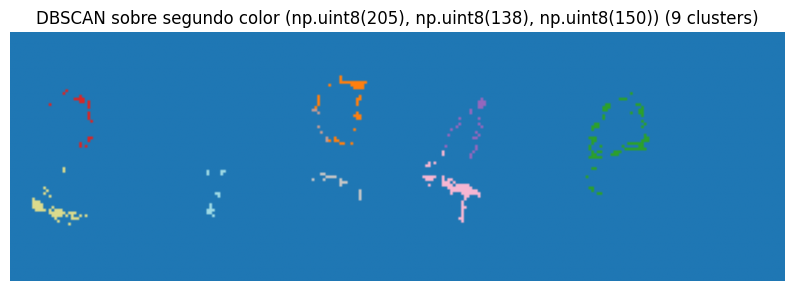

In [8]:
import matplotlib.pyplot as plt

alto, ancho = img_hsv.shape[:2]
canvas = np.zeros((alto, ancho), dtype=np.int32)

for (y, x), label in zip(puntos_muestra, labels):
    canvas[y, x] = label + 1

plt.figure(figsize=(10, 6))
plt.imshow(canvas, cmap="tab20")
plt.title(f"DBSCAN sobre segundo color {segundo_color} ({n_clusters} clusters)")
plt.axis("off")
plt.show()

In [9]:
def calcular_clusters_imagen(imagen,getImage=True):
    i,j,k = imagen.shape
    dicc = {}
    for a in range(i):
        for b in range(j):
            pixel = tuple(imagen[a, b, :])
            dicc[pixel] = dicc.get(pixel,0) + 1
    color_mayor = max(dicc, key=dicc.get)
    top_colores = sorted(dicc.items(), key=lambda item: item[1], reverse=True)
    segundo_color = top_colores[1][0]
    mascara = np.all(imagen == segundo_color, axis=-1)

    puntos = np.argwhere(mascara)

    if len(puntos) > 50000:
        indices = np.random.choice(len(puntos), size=50000, replace=False)
        puntos_muestra = puntos[indices]
    else:
        puntos_muestra = puntos

    db = DBSCAN(eps=15, min_samples=5)
    labels = db.fit_predict(puntos_muestra)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_ruido = list(labels).count(-1)

    alto, ancho = img_hsv.shape[:2]
    canvas = np.zeros((alto, ancho), dtype=np.int32)

    for (y, x), label in zip(puntos_muestra, labels):
        canvas[y, x] = label + 1
        
    if getImage:
        plt.figure(figsize=(10, 6))
        plt.imshow(canvas, cmap="tab20")
        plt.title(f"DBSCAN sobre segundo color {segundo_color} ({n_clusters} clusters)")
        plt.axis("off")
        plt.show()
    return n_clusters

## Ejemplos de clasificación relacizados por DBSCAN

  0%|          | 0/5 [00:00<?, ?it/s]

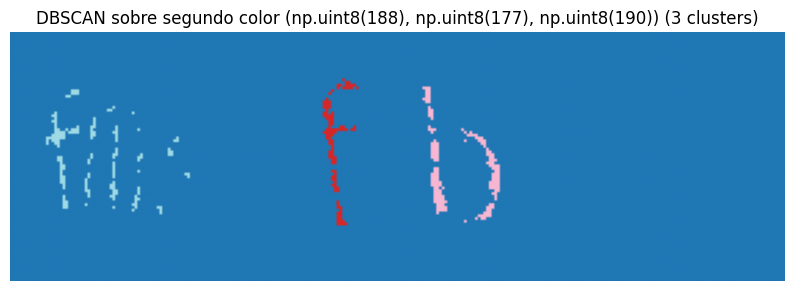

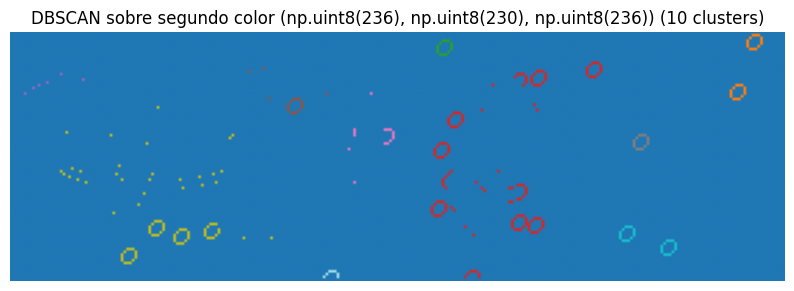

 40%|████      | 2/5 [00:00<00:00, 12.11it/s]

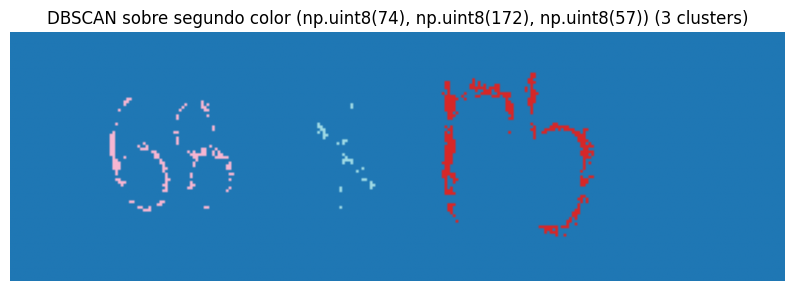

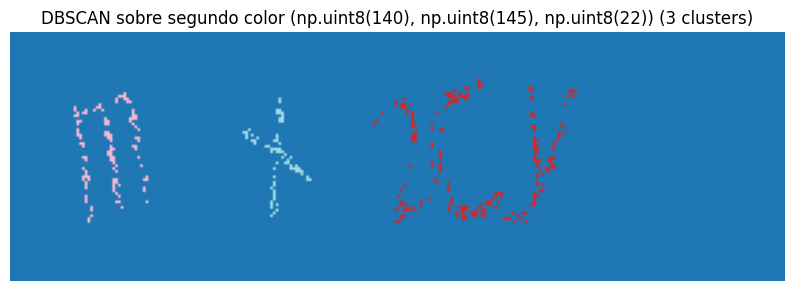

 80%|████████  | 4/5 [00:00<00:00, 11.92it/s]

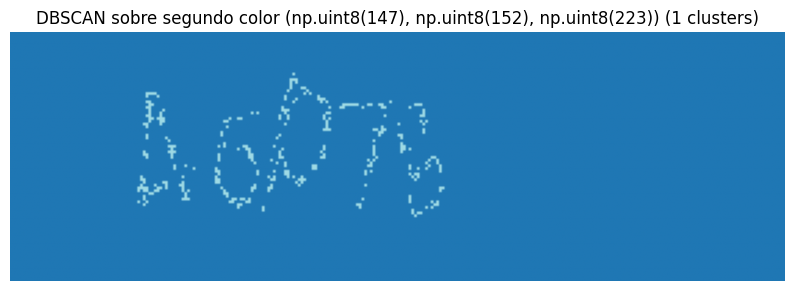

100%|██████████| 5/5 [00:00<00:00, 11.59it/s]


In [10]:
k = max(1, int(len(files) * 0.001))
files_sample = random.sample(files, k)
_ = [calcular_clusters_imagen(getImage(file)) for file in tqdm(files_sample)]

decimos que dbscan clasifico correctamente en el caso de haber conseguido 5 clusters, debido a que tenemos unas 5 letras a clasificar.

In [73]:
k = max(1, int(len(files) * 0.01))
files_sample = random.sample(files, k)
clusters = [calcular_clusters_imagen(getImage(file),getImage=False) for file in tqdm(files_sample)]

100%|██████████| 55/55 [00:01<00:00, 47.45it/s]


Total de muestras analizadas: 55
Media: 5.36
Mediana: 3
Moda: 3
Desviación estándar: 4.14


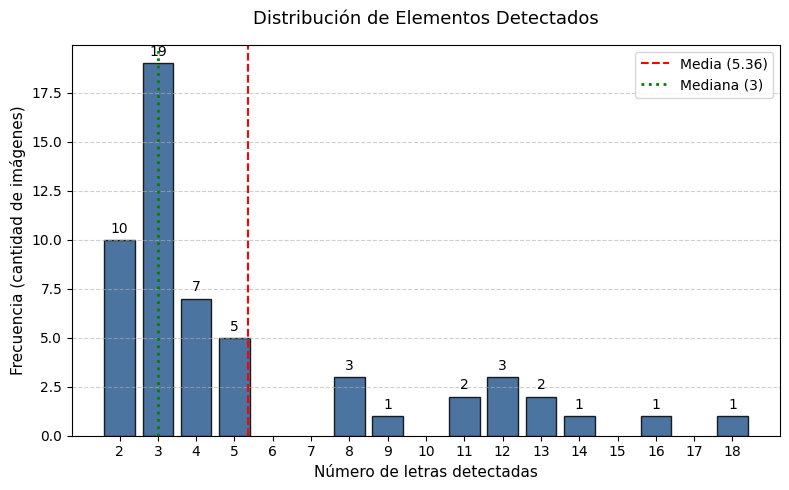

In [74]:
import matplotlib.pyplot as plt
from collections import Counter
import statistics

media = statistics.mean(clusters)
mediana = statistics.median(clusters)
try:
    moda = statistics.mode(clusters)
except statistics.StatisticsError:
    moda = statistics.multimode(clusters)

desv_estandar = statistics.stdev(clusters) if len(clusters) > 1 else 0

print(f"Total de muestras analizadas: {len(clusters)}")
print(f"Media: {media:.2f}")
print(f"Mediana: {mediana}")
print(f"Moda: {moda}")
print(f"Desviación estándar: {desv_estandar:.2f}")

conteo = Counter(clusters)
valores = sorted(conteo.keys())
frecuencias = [conteo[v] for v in valores]

plt.figure(figsize=(8, 5))
barras = plt.bar(valores, frecuencias, color="#2b5c8f", edgecolor="black", alpha=0.85)

for barra in barras:
    altura = barra.get_height()
    plt.annotate(f"{altura}",
                 xy=(barra.get_x() + barra.get_width() / 2, altura),
                 xytext=(0, 3),
                 textcoords="offset points",
                 ha="center", va="bottom", fontsize=10)

plt.axvline(media, color="red", linestyle="--", linewidth=1.5, label=f"Media ({media:.2f})")
plt.axvline(mediana, color="green", linestyle=":", linewidth=2, label=f"Mediana ({mediana})")

plt.title("Distribución de Elementos Detectados", fontsize=13, pad=15)
plt.xlabel("Número de letras detectadas", fontsize=11)
plt.ylabel("Frecuencia (cantidad de imágenes)", fontsize=11)
plt.xticks(range(min(valores), max(valores) + 1))
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

As observed, DBSCAN fails to segment overlapping characters effectively. Given this limitation, we explore alternative unsupervised segmentation techniques.

A good technique should get 5 clusters, one for each character.

In [69]:
class bounding_box_coordenates:
    def __init__(self, x, y):
        self.minx = x
        self.maxx = x
        self.miny = y
        self.maxy = y
        
    def update(self, x, y):
            min_x = min(x) if hasattr(x, '__iter__') else x
            max_x = max(x) if hasattr(x, '__iter__') else x
            min_y = min(y) if hasattr(y, '__iter__') else y
            max_y = max(y) if hasattr(y, '__iter__') else y


            self.minx = min(self.minx, min_x)
            self.maxx = max(self.maxx, max_x)
            self.miny = min(self.miny, min_y)
            self.maxy = max(self.maxy, max_y)

    @property
    def box(self):
        """Devuelve (minx, miny, maxx, maxy)"""
        return int(self.minx), int(self.miny), int(self.maxx), int(self.maxy)

    @property
    def dimensions(self):
        """Devuelve ancho (width) y alto (height)"""
        return (self.maxx - self.minx), (self.maxy - self.miny)
    
def calc_box(puntos_muestra, labels):
    slabels = list(set(labels))
    coordenadas_puntos = {}
    for l in slabels:
        mask = labels == l
        puntos_maskeados = puntos_muestra[mask]
        coords = bounding_box_coordenates(puntos_maskeados[0][1],puntos_muestra[0][0])

        ys = puntos_maskeados[:, 0]
        xs = puntos_maskeados[:, 1]

        coords.update(xs, ys)
        coordenadas_puntos[l] =  coords
    return coordenadas_puntos

def recortar_y_mostrar(imagen, x_min, y_min, x_max, y_max, padding=0):
    """
    Recorta una región de la imagen y la muestra usando matplotlib.
    Las coordenadas se asumen como:
      x_min, x_max -> columnas (ancho)
      y_min, y_max -> filas (alto)
    """
    alto, ancho = imagen.shape[:2]

    x1 = max(0, int(x_min) - padding)
    y1 = max(0, int(y_min) - padding)
    x2 = min(ancho, int(x_max) + padding + 1)
    y2 = min(alto, int(y_max) + padding + 1)

    recorte = imagen[y1:y2, x1:x2]

    plt.figure(figsize=(4, 4))
    if len(imagen.shape) == 2:
        plt.imshow(recorte, cmap="gray")
    else:
        plt.imshow(recorte)
        
    plt.title(f"Recorte ({x2 - x1}x{y2 - y1} px)")
    plt.axis("off")
    plt.show()

    return recorte

def calcular_clusters_recortar_imagen(imagen,getImage=True):
    i,j,k = imagen.shape
    dicc = {}
    for a in range(i):
        for b in range(j):
            pixel = tuple(imagen[a, b, :])
            dicc[pixel] = dicc.get(pixel,0) + 1
    color_mayor = max(dicc, key=dicc.get)
    top_colores = sorted(dicc.items(), key=lambda item: item[1], reverse=True)
    segundo_color = top_colores[1][0]
    mascara = np.all(imagen == segundo_color, axis=-1)

    puntos = np.argwhere(mascara)

    if len(puntos) > 50000:
        indices = np.random.choice(len(puntos), size=50000, replace=False)
        puntos_muestra = puntos[indices]
    else:
        puntos_muestra = puntos

    db = DBSCAN(eps=15, min_samples=5)
    labels = db.fit_predict(puntos_muestra)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_ruido = list(labels).count(-1)
    
    boxs = calc_box(puntos_muestra, labels)
    for l, p in boxs.items():
        min_x, min_y, max_x, max_y = p.box
        recortar_y_mostrar(imagen, min_x, min_y, max_x, max_y)
    alto, ancho = img_hsv.shape[:2]
    canvas = np.zeros((alto, ancho), dtype=np.int32)

    for (y, x), label in zip(puntos_muestra, labels):
        canvas[y, x] = label + 1
        
    if getImage:
        plt.figure(figsize=(10, 6))
        plt.imshow(canvas, cmap="tab20")
        plt.title(f"DBSCAN sobre segundo color {segundo_color} ({n_clusters} clusters)")
        plt.axis("off")
        plt.show()
    return puntos_muestra, labels

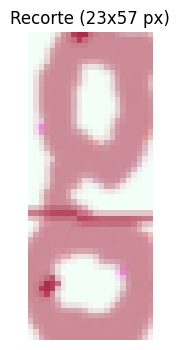

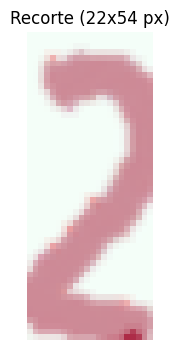

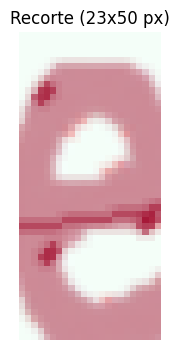

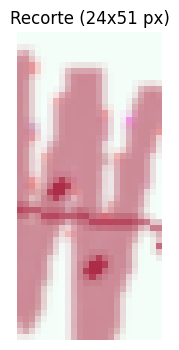

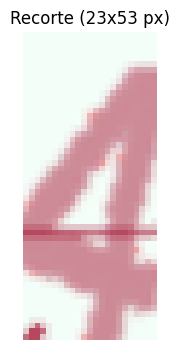

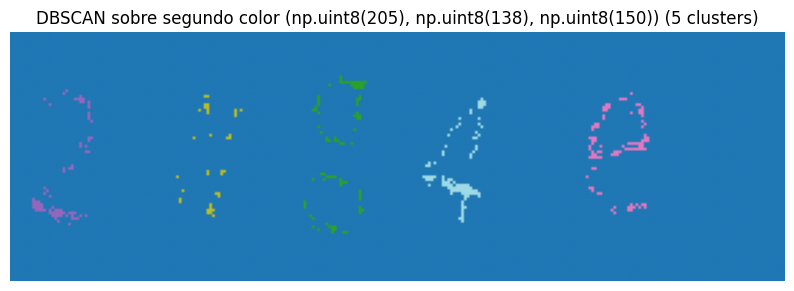

In [72]:
puntos_muestra, labels = calcular_clusters_recortar_imagen(getImage(files[0]))

# Erosion technique

In [ ]:
import cv2
import numpy as np


def segmentar_digitos_erosion(imagen, kernel_size=3):
    pixels = imagen.reshape(-1, imagen.shape[-1])
    colores, counts = np.unique(pixels, axis=0, return_counts=True)
    segundo_color = tuple(colores[np.argsort(-counts)[1]])
    mascara = np.all(imagen == segundo_color, axis=-1).astype(np.uint8)

    kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (kernel_size, kernel_size)
    )
    mascara_erosionada = cv2.erode(mascara, kernel, iterations=1)

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        mascara_erosionada
    )

    min_area = 50
    digitos_validos = [
        i for i in range(1, num_labels) if stats[i, cv2.CC_STAT_AREA] >= min_area
    ]

    return len(digitos_validos), labels

In [ ]:
k = max(1, int(len(files) * 0.01))
files_sample = random.sample(files, k)
clusters = [segmentar_digitos_erosion(getImage(file)) for file in tqdm(files_sample)]

100%|██████████| 99/99 [00:02<00:00, 46.71it/s]


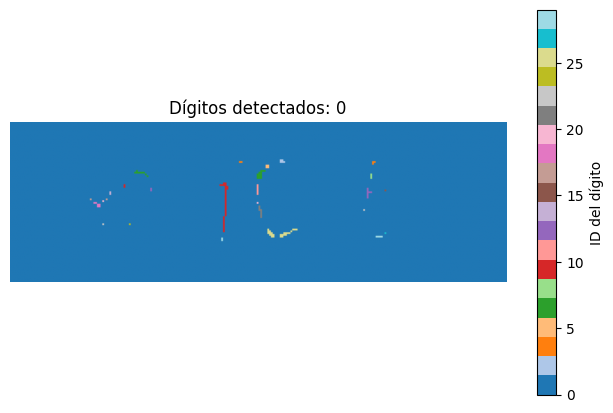

In [ ]:
n_digitos, mapa_clusters = clusters[0]

plt.figure(figsize=(8, 5))
plt.imshow(mapa_clusters, cmap="tab20")
plt.title(f"Dígitos detectados: {n_digitos}")
plt.axis("off")
plt.colorbar(label="ID del dígito")
plt.show()

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

img = Image.open(f"{folder}{files[0]}").convert("L")
img_np = np.array(img)

_, binaria = cv2.threshold(
    img_np, 200, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU
)

kernel_linea = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 3))
sin_linea = cv2.morphologyEx(binaria, cv2.MORPH_OPEN, kernel_linea)

kernel_ruido = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
limpia = cv2.morphologyEx(sin_linea, cv2.MORPH_OPEN, kernel_ruido)

num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(limpia)

min_area = 40
cajas = []
for i in range(1, num_labels):
    x, y, w, h, area = stats[i]
    if area >= min_area:
        cajas.append((x, y, w, h))

cajas = sorted(cajas, key=lambda c: c[0])
print(f"Caracteres detectados: {len(cajas)}")

Caracteres detectados: 4


# Colors islands

I think I can delete the noisy selecting the second color of an image

In [ ]:
def calcular_clusters_imagen(imagen,getImage=True):
    i,j,k = imagen.shape
    dicc = {}
    for a in range(i):
        for b in range(j):
            pixel = tuple(imagen[a, b, :])
            dicc[pixel] = dicc.get(pixel,0) + 1
    top_colores = sorted(dicc.items(), key=lambda item: item[1], reverse=True)
    segundo_color = top_colores[1][0]
    mascara = np.all(imagen == segundo_color, axis=-1)

    result = np.full_like(imagen, fill_value=255)
    result[mascara] = segundo_color
    return result

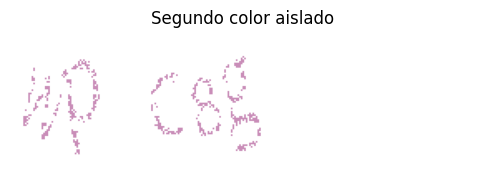

In [ ]:

imagen_procesada = calcular_clusters_imagen(getImage(files[0]))

imagen_rgb = cv2.cvtColor(imagen_procesada, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 4))
plt.imshow(imagen_rgb)
plt.axis("off") 
plt.title("Segundo color aislado")
plt.show()